# Pesos óptimos del ridge filter (mínimos cuadrados acotados)

Calcula los pesos (anchos de escalón) del ridge que dan la dosis más plana, a partir de la base $B_t(x)$ simulada con láminas uniformes de PLA (casos `slab_tNN`, NN = t en décimas de mm: 00, 02, ..., 22).

$$D(x) = \sum_i w_i B_{t_i}(x), \qquad w_i \ge w_{min}, \qquad \sum_i w_i = 1, \qquad t_i = 0, 0.2, \ldots, (n-1)\cdot 0.2\ \text{mm}$$

Se minimiza $\|A w - 1\|^2$ sobre la ventana $[D - T_{max}, D]$ y luego se normaliza $w$; el nivel de dosis es libre.

## 1. Imports

In [31]:
import glob, os, re
import numpy as np
from types import SimpleNamespace
from scipy.optimize import lsq_linear
import matplotlib.pyplot as plt


## 2. Parámetros
Reemplazan a los argumentos de `argparse` del script original.

In [18]:
a = SimpleNamespace(
    glob=r"C:/Users/Usuario/Desktop/Basili Rodriguez Labo 7/Laboratory-VII/phits_ridge_casos_v2/casos/slab_t*/out/bragg_pouch_z.out",
    front=60.28,
    D=2.5,
    Tmax=2.25,
    Ts="1.0,1.25,1.5,2.0,2.25",
    period=0.63,
    res=0.0025,
    block=0,
    nmax=12,
    minw=0.0025,
)

In [19]:
files = sorted(glob.glob(a.glob))
print("Archivos encontrados:", len(files))
print(*files, sep="\n")

Archivos encontrados: 12
C:/Users/Usuario/Desktop/Basili Rodriguez Labo 7/Laboratory-VII/phits_ridge_casos_v2/casos\slab_t00\out\bragg_pouch_z.out
C:/Users/Usuario/Desktop/Basili Rodriguez Labo 7/Laboratory-VII/phits_ridge_casos_v2/casos\slab_t02\out\bragg_pouch_z.out
C:/Users/Usuario/Desktop/Basili Rodriguez Labo 7/Laboratory-VII/phits_ridge_casos_v2/casos\slab_t04\out\bragg_pouch_z.out
C:/Users/Usuario/Desktop/Basili Rodriguez Labo 7/Laboratory-VII/phits_ridge_casos_v2/casos\slab_t06\out\bragg_pouch_z.out
C:/Users/Usuario/Desktop/Basili Rodriguez Labo 7/Laboratory-VII/phits_ridge_casos_v2/casos\slab_t08\out\bragg_pouch_z.out
C:/Users/Usuario/Desktop/Basili Rodriguez Labo 7/Laboratory-VII/phits_ridge_casos_v2/casos\slab_t10\out\bragg_pouch_z.out
C:/Users/Usuario/Desktop/Basili Rodriguez Labo 7/Laboratory-VII/phits_ridge_casos_v2/casos\slab_t12\out\bragg_pouch_z.out
C:/Users/Usuario/Desktop/Basili Rodriguez Labo 7/Laboratory-VII/phits_ridge_casos_v2/casos\slab_t14\out\bragg_pouch_z.out

## 3. Definición de funciones

In [20]:
def load(path, block, front):
    """Lee un archivo .out y devuelve (x en mm desde el frente, dosis) del bloque pedido."""
    blocks = [[]]
    for l in open(path):
        t = l.split()
        if len(t) == 4:
            try:
                v = [float(x) for x in t]
            except ValueError:
                continue
            if blocks[-1] and v[0] < blocks[-1][-1][0]:
                blocks.append([])
            blocks[-1].append(v)
    R = np.array(blocks[block])
    return (0.5*(R[:, 0] + R[:, 1]) - front)*10.0, R[:, 2]


def analytic(N, p=1.827):
    """Pesos analíticos para un ridge de N escalones."""
    aa = 1 - 1/p
    ww = np.array([((i+0.5)**aa - max(i-0.5, 0)**aa)/aa for i in range(N)])
    return ww/ww.sum()


def rounded(wt, res, period):
    """Redondea los anchos a múltiplos de la resolución de impresión y compensa en el escalón 0."""
    full = np.round(wt*period/res)*res
    full[0] += period - full.sum()
    return full/period

## 4. Carga de la base de láminas

In [21]:
files = sorted(glob.glob(a.glob))
basis = {}
for f in files:
    m = re.search(r"slab_t(\d\d)", f)
    if not m:
        continue
    t = int(m.group(1))/10.0
    basis[round(t, 1)] = load(f, a.block, a.front)

ts = sorted(basis)[:a.nmax]
if len(ts) < 3:
    raise RuntimeError("faltan casos slab_tNN: encontrados %s" % ts)
print("Espesores cargados (mm):", ts)

Espesores cargados (mm): [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2]


In [22]:
import os

print("Carpeta actual:")
print(os.getcwd())

print("\nContenido de la carpeta:")
print(os.listdir("."))

Carpeta actual:
c:\Users\Usuario\Desktop\Basili Rodriguez Labo 7\Laboratory-VII\phits_ridge_casos_v2\herramientas\jupyter

Contenido de la carpeta:
['check_exact.ipynb', 'check_geom.ipynb', 'espectro_incidente.ipynb', 'eval_pouch.ipynb', 'gen_ridge.ipynb', 'make_cases.ipynb', 'nnls_weights.ipynb', 'ridge_design.ipynb', 'ridge_vs_espectro.ipynb', 'scipy-1.10.1-cp38-cp38-win_amd64.whl', 'test_sintetico.ipynb']


In [23]:
import glob

print(glob.glob("casos/*"))

[]


In [24]:
import os

print(os.getcwd())

c:\Users\Usuario\Desktop\Basili Rodriguez Labo 7\Laboratory-VII\phits_ridge_casos_v2\herramientas\jupyter


## 5. Ajuste por mínimos cuadrados acotados

In [25]:
xg = np.arange(0.0, a.D + 0.3, 0.02)
A = np.array([np.interp(xg, *basis[t]) for t in ts]).T   # columnas = B_t en la grilla común
win = (xg >= a.D - a.Tmax) & (xg <= a.D)
wmin = a.minw/a.period   # un escalón con peso 0 no se puede construir: cota inferior = ancho mínimo imprimible

sol = lsq_linear(A[win], np.ones(win.sum()), bounds=(np.full(len(ts), wmin), np.inf))
w = sol.x
lvl = 1.0/w.sum()
w = w/w.sum()

## 6. Candidatos a comparar

In [26]:
def cv(wt, T):
    """Coeficiente de variación (%) de la dosis en la ventana [D-T, D]."""
    s = (xg >= a.D - T) & (xg <= a.D)
    d = A[s] @ wt
    return d.std()/d.mean()*100

Ts = [float(v) for v in a.Ts.split(",")]

wr = rounded(w, a.res, a.period)
cands = [("minimos cuadrados (continuo)", w),
         ("min. cuadrados redond. %.0f um" % (a.res*1e4), wr)]

for N in (9, 10, 11, 12):
    if N <= len(ts):
        cands.append(("analitico N%d" % N, np.pad(analytic(N), (0, len(ts)-N))))

orig = np.array([0.18, 0.09, 0.07, 0.06, 0.05, 0.05, 0.05, 0.04, 0.04])
orig = orig/orig.sum()
if len(ts) >= 9:
    cands.append(("ridge original 9", np.pad(orig, (0, len(ts)-9))))

## 7. Resultados

In [27]:
print("Espesores de PLA disponibles (mm):", ts)
print("Ventana de ajuste: x en [%.2f, %.2f] mm desde el frente del gel; pileta fija D = %.2f mm\n" % (a.D-a.Tmax, a.D, a.D))
print("Pesos por espesor (fraccion de area):")
print("  t(mm)   " + "  ".join("%5.1f" % t for t in ts))
for name, wt in cands:
    print("  %-30s" % name + "  ".join("%5.3f" % v for v in wt))

Espesores de PLA disponibles (mm): [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2]
Ventana de ajuste: x en [0.25, 2.50] mm desde el frente del gel; pileta fija D = 2.50 mm

Pesos por espesor (fraccion de area):
  t(mm)     0.0    0.2    0.4    0.6    0.8    1.0    1.2    1.4    1.6    1.8    2.0    2.2
  minimos cuadrados (continuo)  0.538  0.006  0.016  0.056  0.051  0.050  0.049  0.048  0.045  0.045  0.048  0.049
  min. cuadrados redond. 25 um  0.544  0.008  0.016  0.056  0.052  0.048  0.048  0.048  0.044  0.044  0.048  0.048
  analitico N9                  0.277  0.179  0.119  0.095  0.081  0.071  0.065  0.059  0.055  0.000  0.000  0.000
  analitico N10                 0.264  0.170  0.113  0.090  0.077  0.068  0.061  0.056  0.052  0.049  0.000  0.000
  analitico N11                 0.252  0.162  0.108  0.086  0.073  0.065  0.059  0.054  0.050  0.047  0.044  0.000
  analitico N12                 0.242  0.156  0.103  0.082  0.070  0.062  0.056  0.052  0.048  0.045  0.043 

In [28]:
print("CV (%) de la dosis en la ventana [D-T, D]:")
print("  %-30s" % "T (mm)" + "  ".join("%6.2f" % T for T in Ts))
for name, wt in cands:
    print("  %-30s" % name + "  ".join("%6.2f" % cv(wt, T) for T in Ts))

CV (%) de la dosis en la ventana [D-T, D]:
  T (mm)                          1.00    1.25    1.50    2.00    2.25
  minimos cuadrados (continuo)    3.23    3.13    3.03    2.93    2.90
  min. cuadrados redond. 25 um    3.22    3.14    3.04    2.95    2.95
  analitico N9                    3.85    3.76    3.75    8.43   11.11
  analitico N10                   3.85    3.76    3.75    5.65    8.24
  analitico N11                   3.85    3.76    3.75    4.09    5.85
  analitico N12                   3.85    3.76    3.75    4.08    4.48
  ridge original 9                4.53    4.43    4.24    7.57   10.14


## 8. Anchos completos para `gen_ridge.py --widths`

In [29]:
full = (wr*a.period)[::-1]   # del más grueso (índice n-1) al de espesor 0
keep = [x for x in full]
while keep and keep[0] <= 0:   # descartar escalones gruesos con peso 0
    keep.pop(0)

print("anchos completos (cm) para gen_ridge.py --widths, escalon 1 (grueso) -> espesor 0 (%d escalones, tmax %.1f mm):" % (len(keep), 0.2*(len(keep)-1)))
print(",".join("%.4f" % x for x in keep))
print("nivel de dosis relativo del ridge optimizado = %.3f (unidades del tally por fuente)" % lvl)

anchos completos (cm) para gen_ridge.py --widths, escalon 1 (grueso) -> espesor 0 (12 escalones, tmax 2.2 mm):
0.0300,0.0300,0.0275,0.0275,0.0300,0.0300,0.0300,0.0325,0.0350,0.0100,0.0050,0.3425
nivel de dosis relativo del ridge optimizado = 1.572 (unidades del tally por fuente)


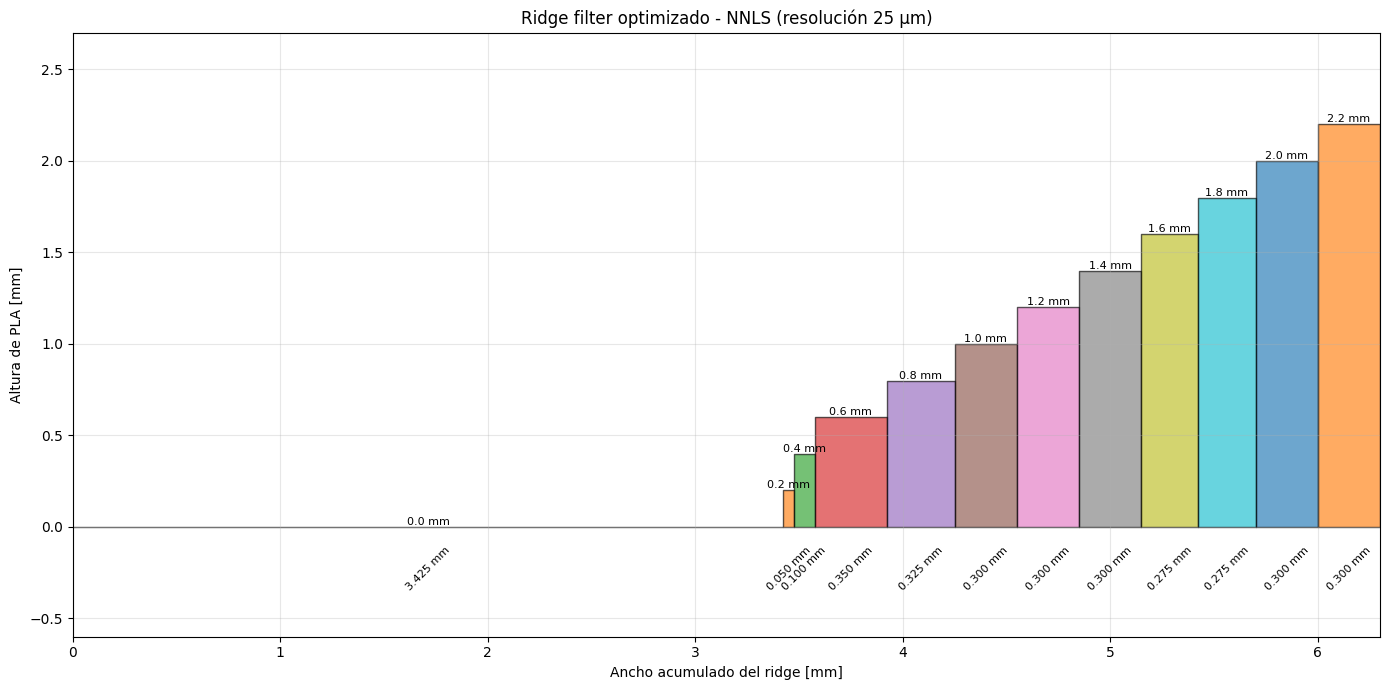

DIMENSIONES DE LOS ESCALONES
---------------------------------------------
Escalón | Altura [mm] | Ancho [mm]
---------------------------------------------
      1 |        0.00 |      3.425
      2 |        0.20 |      0.050
      3 |        0.40 |      0.100
      4 |        0.60 |      0.350
      5 |        0.80 |      0.325
      6 |        1.00 |      0.300
      7 |        1.20 |      0.300
      8 |        1.40 |      0.300
      9 |        1.60 |      0.275
     10 |        1.80 |      0.275
     11 |        2.00 |      0.300
     12 |        2.20 |      0.300
---------------------------------------------
Ancho total: 6.300 mm


In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Pesos optimizados redondeados a 25 um
wt = cands[1][1]

# Anchos de los escalones [mm]
widths = wt * a.period * 10

# Alturas de los escalones [mm]
heights = np.array(ts)

# Posiciones acumuladas
edges = np.concatenate(([0], np.cumsum(widths)))

fig, ax = plt.subplots(figsize=(14, 7))

for i in range(len(ts)):
    x0 = edges[i]
    x1 = edges[i+1]
    h = heights[i]

    # Dibujar escalón
    ax.fill_between(
        [x0, x1],
        [h, h],
        step="post",
        alpha=0.65,
        edgecolor="black"
    )

    # Ancho
    ax.annotate(
        f"{widths[i]:.3f} mm",
        ((x0+x1)/2, -0.10),
        ha="center",
        va="top",
        fontsize=8,
        rotation=45
    )

    # Altura
    ax.annotate(
        f"{h:.1f} mm",
        ((x0+x1)/2, h),
        ha="center",
        va="bottom",
        fontsize=8
    )

ax.set_xlabel("Ancho acumulado del ridge [mm]")
ax.set_ylabel("Altura de PLA [mm]")
ax.set_title("Ridge filter optimizado - NNLS (resolución 25 µm)")

ax.set_xlim(0, a.period*10)
ax.set_ylim(-0.6, max(heights)+0.5)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("DIMENSIONES DE LOS ESCALONES")
print("-"*45)
print("Escalón | Altura [mm] | Ancho [mm]")
print("-"*45)

for i, (h, w) in enumerate(zip(heights, widths)):
    print(f"{i+1:7d} | {h:11.2f} | {w:10.3f}")

print("-"*45)
print(f"Ancho total: {widths.sum():.3f} mm")

In [34]:
# Recuperar los pesos redondeados a 25 um
wt = next(w for name, w in cands
          if name == "min. cuadrados redond. 25 um")

# Anchos completos en cm
widths_cm = wt * a.period

# Invertir el orden:
# NNLS: 0 -> 2.2 mm
# gen_ridge: 2.2 -> 0 mm
widths_gen = widths_cm[::-1]

print("Anchos para gen_ridge.py (cm):")
print(",".join("%.8f" % w for w in widths_gen))

print("\nSuma de anchos:", widths_gen.sum(), "cm")

Anchos para gen_ridge.py (cm):
0.03000000,0.03000000,0.02750000,0.02750000,0.03000000,0.03000000,0.03000000,0.03250000,0.03500000,0.01000000,0.00500000,0.34250000

Suma de anchos: 0.6300000000000001 cm
